# Deterministic autoencoder for MNIST

An encoder maps each 28 × 28 image to a single latent vector $z$. A decoder maps that vector back to 784 pixel logits. Both networks are small multilayer perceptrons. The bottleneck makes the network learn a compressed representation, and the same input always produces the same code.

Training uses the image as its own target. Binary cross-entropy with logits is summed over pixels and averaged across the batch. Digit labels are used only to annotate examples. A VAE adds a latent probability distribution, sampling, and a KL term. This autoencoder has no learned prior, so arbitrary samples from a standard normal are not expected to decode to plausible digits.

In [ ]:
import os

import torch

# In Google Colab uncomment these lines:
# !wget https://raw.githubusercontent.com/IvanSol/ml-course/refs/heads/master/Class13_VAE/models.py
# !wget https://raw.githubusercontent.com/IvanSol/ml-course/refs/heads/master/Class13_VAE/plots.py
# !wget https://raw.githubusercontent.com/IvanSol/ml-course/refs/heads/master/Class13_VAE/training.py

from plots import image_grid, learning_curves
from training import Settings, fit_autoencoder, loader, mnist, setup, split_train

quick = os.getenv("VAE_QUICK", "0") == "1"
settings = Settings(quick=quick, epochs=1 if quick else 15)
device = setup(settings)
mode = "QUICK MODE (smoke test)" if quick else "Full experiment"
print(f"{mode} | device={device} | {settings}")

Full experiment | device=cuda | Settings(seed=42, latent_dim=16, hidden_dim=256, batch_size=256, epochs=15, learning_rate=0.001, beta=1.0, quick=False)


## Fit the autoencoder

Use the same seeded training and validation split as the conditional VAE. Validation reconstruction loss selects the checkpoint. Change the latent dimension in the settings cell to explore how the bottleneck affects reconstruction.

Loaded runs\autoencoder-full-656d54714574.pt (epoch 15)


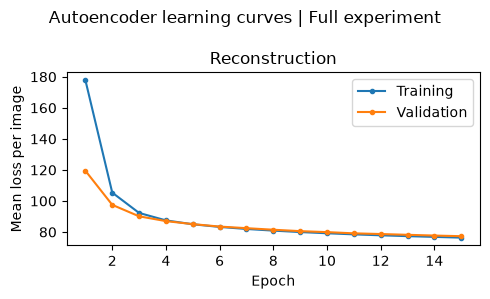

In [3]:
train, validation, _ = split_train(mnist(), settings)
model, history = fit_autoencoder(settings, train, validation, device)
learning_curves(history, mode, metrics=("reconstruction",), title="Autoencoder learning curves")

## Reconstruct held-out digits

Encode images from the official test set and decode their latent vectors. Apply sigmoid to turn logits into displayable intensities. Look for strokes that disappear or blur when the bottleneck cannot retain all the input details.

Images: (8, 1, 28, 28) | latent codes: (8, 16)


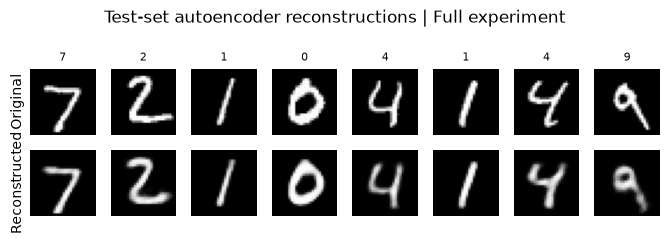

In [4]:
images, labels = next(iter(loader(mnist(train=False), settings)))
images = images[:8].to(device)
with torch.inference_mode():
    codes = model.encode(images)
    restored = model.decode(codes).sigmoid()
print(f"Images: {tuple(images.shape)} | latent codes: {tuple(codes.shape)}")
image_grid(
    torch.stack((images, restored)).cpu().numpy(),
    f"Test-set autoencoder reconstructions | {mode}",
    row_labels=["Original", "Reconstructed"],
    column_labels=labels[:len(images)].tolist(),
)

## Interpolate between two encoded images

Interpolate between the latent codes of two test digits. The endpoints are the autoencoder's reconstructions of the two inputs. Intermediate frames show how the decoder behaves between those specific codes.

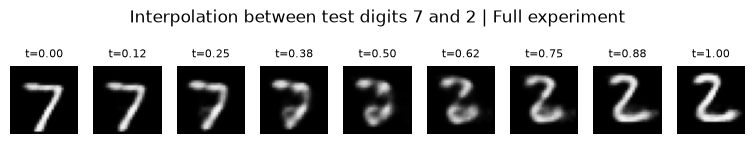

In [5]:
weights = torch.linspace(0, 1, 9, device=device)
with torch.inference_mode():
    path = torch.lerp(codes[0], codes[1], weights[:, None])
    frames = model.decode(path).sigmoid()
image_grid(
    frames.cpu().numpy()[None],
    f"Interpolation between test digits {labels[0].item()} and {labels[1].item()} | {mode}",
    column_labels=[f"t={weight:.2f}" for weight in weights.tolist()],
)

16

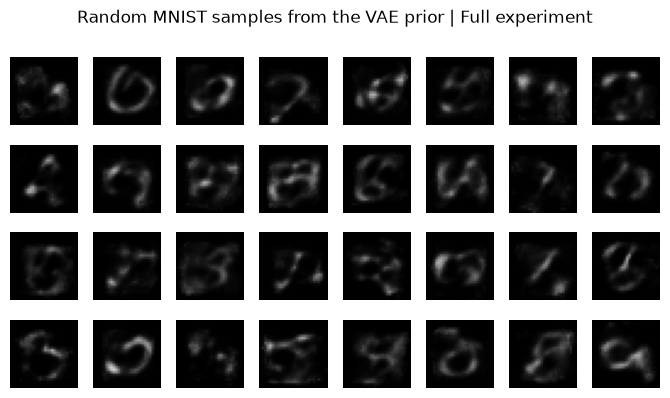

In [11]:
rows, columns = 4, 8
sample_seed = settings.seed + 50
rng = torch.Generator(device=device).manual_seed(sample_seed)

with torch.inference_mode():
    latent = torch.randn(rows * columns, model.latent_dim, generator=rng, device=device)
    generated = model.decode(latent).sigmoid()

image_grid(
    generated.cpu().numpy().reshape(rows, columns, 28, 28),
    f"Random MNIST samples from the VAE prior | {mode}",
)

## From a deterministic autoencoder to a VAE

The encoder now gives each image a distribution $q(z\mid x)$ with a mean and diagonal log variance. During training, it draws $z = \mu + \exp(0.5\,\log\sigma^2)\odot\epsilon$, where $\epsilon\sim\mathcal{N}(0,I)$. The decoder reconstructs the image from this sample. The objective adds $\beta$ times the KL divergence to the reconstruction loss, encouraging the posterior to stay close to the standard normal prior. Here $\beta=1$.

This section fits or reloads the unconditional VAE used in the few-shot notebook. It uses that notebook's split, which holds out a support pool in addition to validation. Training uses images alone.

Loaded runs\unconditional-full-656d54714574.pt (epoch 15)


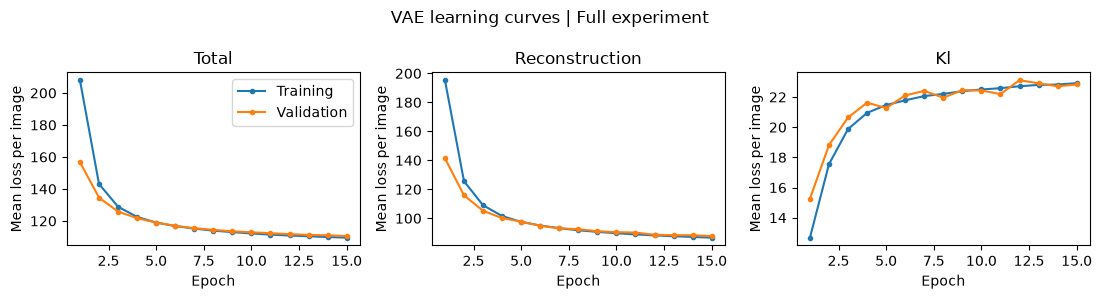

In [ ]:
from training import fit_or_load

vae_train, vae_validation, _ = split_train(mnist(), settings, include_support=True)
vae, vae_history = fit_or_load(
    settings, vae_train, vae_validation, device, conditional=False,
)
learning_curves(vae_history, mode)

## Generate new digits from the prior

Draw independent latent vectors from $p(z)=\mathcal{N}(0,I)$ and pass them directly to the decoder. This generates digits without an input image or a class label. Sigmoid turns the decoder logits into pixel probabilities for the grid. The seed makes this particular grid reproducible on the same device. Change `sample_seed` for a different draw.

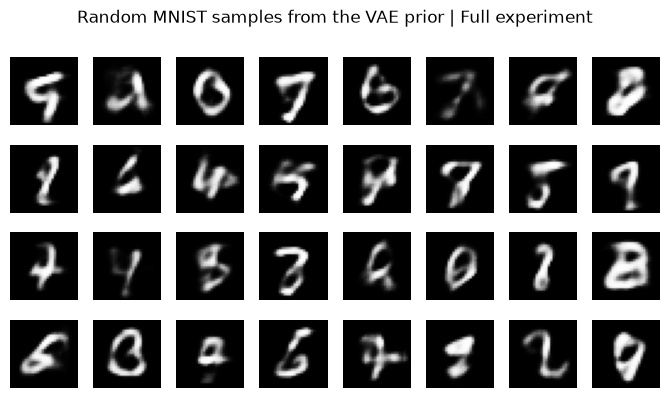

In [ ]:
rows, columns = 4, 8
sample_seed = settings.seed + 50
rng = torch.Generator(device=device).manual_seed(sample_seed)

with torch.inference_mode():
    latent = torch.randn(rows * columns, vae.latent_dim, generator=rng, device=device)
    generated = vae.decode(latent).sigmoid()

image_grid(
    generated.cpu().numpy().reshape(rows, columns, 28, 28),
    f"Random MNIST samples from the VAE prior | {mode}",
)